In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install ultralytics

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

# Cargar un modelo preentrenado (Transfer Learning)
model = YOLO('yolov8n.pt')

# Iniciar el entrenamiento
results = model.train(
    data='/content/drive/MyDrive/dog.v1i.yolov8/data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    project='/content/drive/MyDrive/dog.v1i.yolov8',
    name='entrenamiento_base'
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dog.v1i.yolov8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscrip

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar imagen y convertir a HSV
img = cv2.imread('/content/drive/MyDrive/dog.v1i.yolov8/test/images/19_jpg.rf.c6e72c01fb3df846971cff15d321a16d.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# 2. Umbralización de color (Ejemplo: segmentar tonos marrones/oscuros)
lower_bound = np.array([10, 50, 50])
upper_bound = np.array([30, 255, 255])
mask = cv2.inRange(hsv, lower_bound, upper_bound)

# 3. Filtrado Espacial No Lineal (Eliminar ruido)
mask_filtered = cv2.medianBlur(mask, 5)

# 4. Transformaciones Morfológicas (Cerrar huecos en la silueta)
kernel = np.ones((5,5), np.uint8)
mask_closed = cv2.morphologyEx(mask_filtered, cv2.MORPH_CLOSE, kernel)

# 5. Extracción de Características (Contornos)
contours, _ = cv2.findContours(mask_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

perros_detectados = 0
for cnt in contours:
    area = cv2.contourArea(cnt)
    # Descriptor matemático de tamaño
    if area > 1500:  # Ignorar ruido pequeño
        perros_detectados += 1
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

        # Lógica de tamaño
        tamano = "Grande" if area > 10000 else "Pequeno/Mediano"
        cv2.putText(img, f'{tamano} - Area:{int(area)}', (x, y-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

print(f"Perros contados mediante matemática de contornos: {perros_detectados}")

Perros contados mediante matemática de contornos: 5


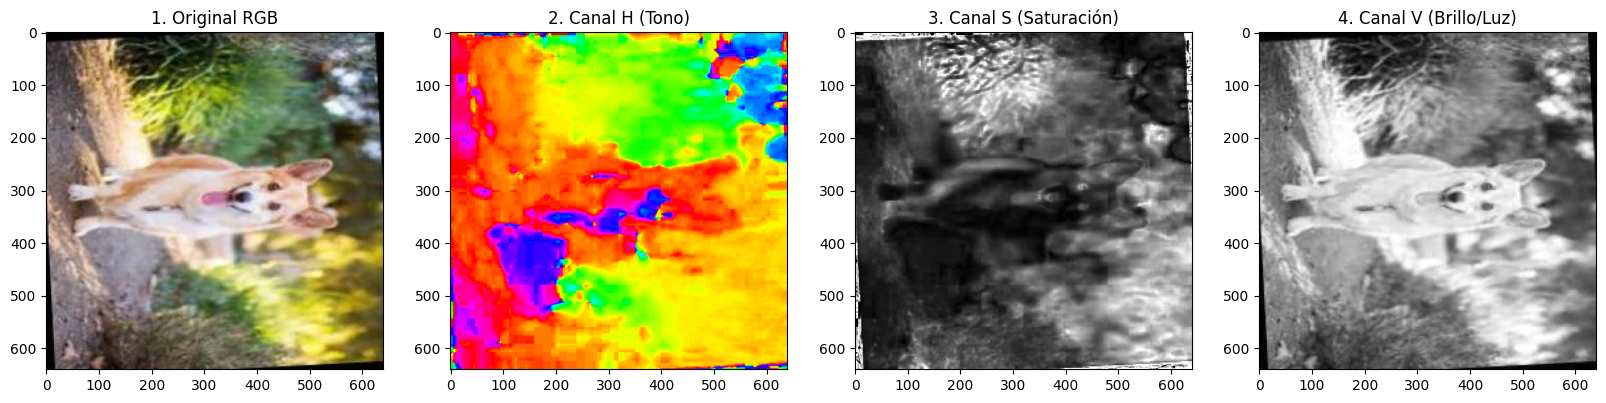

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Reemplaza con la ruta de una foto de tu dataset
img_path = '/content/drive/MyDrive/dog.v1i.yolov8/test/images/19_jpg.rf.c6e72c01fb3df846971cff15d321a16d.jpg'
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Visualizar la imagen original y la descomposición matemática de los 3 canales HSV
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(img_rgb)
axs[0].set_title('1. Original RGB')
axs[1].imshow(hsv[:,:,0], cmap='hsv')
axs[1].set_title('2. Canal H (Tono)')
axs[2].imshow(hsv[:,:,1], cmap='gray')
axs[2].set_title('3. Canal S (Saturación)')
axs[3].imshow(hsv[:,:,2], cmap='gray')
axs[3].set_title('4. Canal V (Brillo/Luz)')
plt.show()

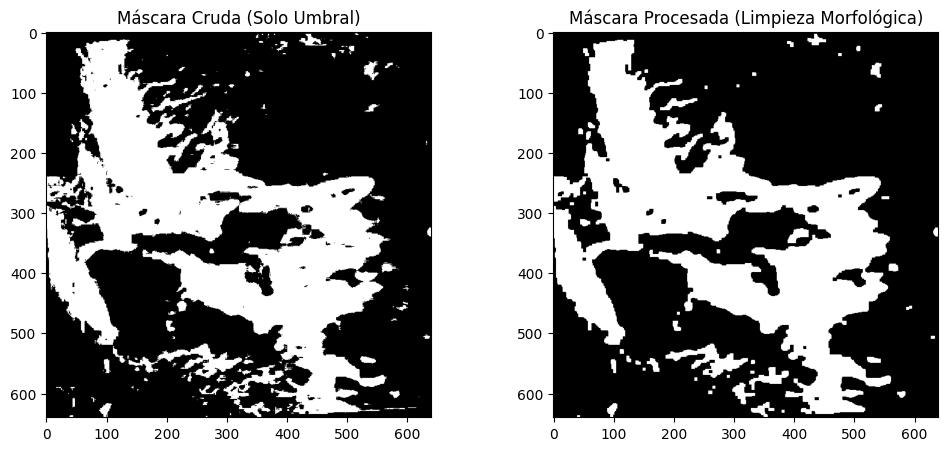

In [ ]:
import numpy as np

# 1. Umbrales matemáticos justificados por el análisis HSV
# H: 0 a 40 (Tonos cálidos/castaños, ignorando el resto del espectro)
# S: 0 a 150 (Baja a media saturación para capturar el blanco y castaño claro)
# V: 120 a 255 (Alto nivel de iluminación)
lower_bound = np.array([0, 0, 120])
upper_bound = np.array([40, 150, 255])

# 2. Umbralización de color
mask = cv2.inRange(hsv, lower_bound, upper_bound)

# 3. Transformaciones Geométricas (Morfológicas) para limpiar la silueta
kernel = np.ones((5,5), np.uint8)
# 'Apertura' elimina el ruido de fondo (píxeles blancos sueltos)
mask_opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
# 'Cierre' rellena los huecos negros dentro de la silueta del perro
mask_closed = cv2.morphologyEx(mask_opened, cv2.MORPH_CLOSE, kernel)

# Visualizar el resultado
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(mask, cmap='gray')
axs[0].set_title('Máscara Cruda (Solo Umbral)')
axs[1].imshow(mask_closed, cmap='gray')
axs[1].set_title('Máscara Procesada (Limpieza Morfológica)')
plt.show()